# 양자컴퓨팅 부트캠프 Day 1: 선형대수학과 단일 큐비트 상태벡터 NumPy 핸즈온 (정답 및 실행 결과)

본 노트북은 **12시간 양자컴퓨팅 부트캠프의 1일차 3교시 실습 교재**입니다.
선형대수학의 복소 벡터 공간, 유니터리 연산자, Born 측정 규칙을 순수 Python과 `numpy`만으로 직접 계산하고 시뮬레이션합니다.

---
### 오늘 실습의 5대 학습 목표
1. **NumPy 복소 행렬과 벡터**: 복소수(`dtype=complex`), 열벡터, 2x2 행렬 표현 및 행렬곱(`@`) 연산자 체득
2. **계산 기저와 유니터리 게이트**: $|0\rangle, |1\rangle$ 열벡터와 $X, Y, Z, H, S, T$ 게이트의 유니터리성($U^* U = I$) 검증
3. **정규화와 Born 측정 규칙**: 상태벡터 크기 보존($\langle\psi|\psi\rangle=1$)과 측정 확률($P(0)=|\alpha|^2, P(1)=|\beta|^2$) 계산
4. **Hadamard 기저 변환과 가역성**: 계산 기저($Z$축)와 중첩 기저($X$축) 상호 변환 및 자기 역원성($H^2=I$) 확인
5. **Shot Noise와 $1/\sqrt{M}$ 표본 수렴**: 반복 측정 횟수($M$)에 따른 통계적 오차 감소를 이론 곡선과 함께 시각화 관찰


In [1]:
from __future__ import annotations

import numpy as np
import matplotlib.pyplot as plt

# 소수점 출력 포맷 설정 (깔끔한 출력을 위해 소수점 4자리까지 표시)
np.set_printoptions(precision=4, suppress=True)

print(f"NumPy version: {np.__version__}")


NumPy version: 2.5.4


## 0. [워밍업] 양자 실습을 위한 3분 NumPy 핵심 생존 규칙

양자역학의 큐비트와 게이트를 다루기 위해 필요한 파이썬/NumPy 문법은 **딱 3가지**입니다:
1. **열벡터와 행렬 선언**: 가로 행마다 대괄호 `[...]`로 감싸서 선언합니다.
   - 열벡터 $\begin{pmatrix} 1 \\ 2 \end{pmatrix}$ $\to$ `np.array([[1], [2]], dtype=complex)` (가로행이 2개!)
   - 2x2 행렬 $\begin{pmatrix} 1 & 0 \\ 0 & -1 \end{pmatrix}$ $\to$ `np.array([[1, 0], [0, -1]], dtype=complex)`
2. **복소수 타입과 허수 표기**: 따옴표 없이 `dtype=complex`를 쓰며, 허수 단위는 $i$ 대신 **`1j`**를 씁니다. (예: `1 + 2j`)
3. **행렬곱 연산자**: 행렬과 벡터의 곱은 `*`가 아니라 **`@`** 기호를 씁니다. (예: `M @ v`)


In [2]:
# [워밍업 예시 실행] 2x2 행렬 M과 2차원 열벡터 v의 곱
v_demo = np.array([[1.0], [2.0]], dtype=complex)        # shape: (2, 1) 열벡터
M_demo = np.array([[1.0, 0.0], [0.0, -1.0]], dtype=complex)  # shape: (2, 2) 행렬

print("행렬 M_demo:")
print(M_demo)
print()
print("벡터 v_demo:")
print(v_demo)
print()
print("행렬곱 M_demo @ v_demo 결과:")
print(M_demo @ v_demo)


행렬 M_demo:
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]

벡터 v_demo:
[[1.+0.j]
 [2.+0.j]]

행렬곱 M_demo @ v_demo 결과:
[[ 1.+0.j]
 [-2.+0.j]]


### [미니 워밍업 과제] 직접 2x2 복소 행렬 $A$ 정의하기
아래의 2x2 행렬 $A$를 `dtype=complex`를 사용하여 NumPy 배열로 직접 정의해 보세요:
$$A = \begin{pmatrix} 1 & 2 \\ 3 & 4 \end{pmatrix}$$


In [3]:
# [정답 0] 2x2 복소 행렬 A 직접 작성
A = np.array([[1.0, 2.0], [3.0, 4.0]], dtype=complex)

# [자가 검증] 아래 코드를 실행해 확인하세요 (수정 불필요)
assert A is not None and A.shape == (2, 2), "A는 (2, 2) 크기의 2차원 행렬이어야 합니다!"
assert np.iscomplexobj(A), "dtype=complex 옵션을 넣어 복소수 행렬로 선언해야 합니다!"
assert np.allclose(A @ np.array([[1], [1]]), [[3], [7]]), "행렬 A의 원소 값이 올바르지 않습니다!"
print("[검증 완료] 2x2 복소 행렬 정의가 정상 확인되었습니다.")


[검증 완료] 2x2 복소 행렬 정의가 정상 확인되었습니다.


## 1. 계산 기저 (Computational Basis) 상태 정의

단일 큐비트의 물리적 상태는 2차원 복소 내적 공간 $\mathbb{C}^2$의 단위 열벡터로 기술됩니다.
가장 기본이 되는 표준 정규직교기저 $|0\rangle$과 $|1\rangle$을 정의합니다:

$$|0\rangle = \begin{pmatrix} 1 \\ 0 \end{pmatrix}, \qquad |1\rangle = \begin{pmatrix} 0 \\ 1 \end{pmatrix}$$


In [4]:
# 2차원 복소 열벡터 정의
KET_0 = np.array([[1.0], [0.0]], dtype=complex)  # |0>
KET_1 = np.array([[0.0], [1.0]], dtype=complex)  # |1>

print("|0> basis vector (shape:", KET_0.shape, "):")
print(KET_0)
print()
print("|1> basis vector (shape:", KET_1.shape, "):")
print(KET_1)


|0> basis vector (shape: (2, 1) ):
[[1.+0.j]
 [0.+0.j]]

|1> basis vector (shape: (2, 1) ):
[[0.+0.j]
 [1.+0.j]]


## 2. 단일 큐비트 유니터리 게이트 (Unitary Gates)

양자 게이트는 닫힌 양자계의 가역적 시간 발전을 나타내며, 선형대수학적으로 **크기를 보존하는 $2 \times 2$ 유니터리 행렬**로 표현됩니다:

$$U^* U = U U^* = I \iff U^{-1} = U^*$$

### 유니터리 판별 도구 (제공)
행렬이 크기와 직교성을 보존하는지 수치적으로 판별하는 도우미 함수 `is_unitary()`를 제공합니다:


In [5]:
def is_unitary(matrix: np.ndarray, tol: float = 1e-9) -> bool:
    """행렬 U가 U^* U = I 를 만족하는지 np.allclose를 통해 수치적으로 검증합니다."""
    dim = matrix.shape[0]
    identity = np.eye(dim, dtype=complex)
    product = matrix.conj().T @ matrix  # 켤레전치 행렬곱
    return bool(np.allclose(product, identity, atol=tol))

# 기본 Pauli 게이트 정의 예시
GATE_I = np.array([[1, 0], [0, 1]], dtype=complex)
GATE_X = np.array([[0, 1], [1, 0]], dtype=complex)
GATE_Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
GATE_Z = np.array([[1, 0], [0, -1]], dtype=complex)

print("[기본 Pauli 게이트 유니터리성 검증]")
for name, g in [("I", GATE_I), ("X", GATE_X), ("Y", GATE_Y), ("Z", GATE_Z)]:
    print(f"  - Gate {name}: Unitary = {is_unitary(g)}")


[기본 Pauli 게이트 유니터리성 검증]
  - Gate I: Unitary = True
  - Gate X: Unitary = True
  - Gate Y: Unitary = True
  - Gate Z: Unitary = True


### [실습 과제 1] Hadamard 게이트($H$) 및 위상 게이트($S, T$) 직접 정의하기
아래 수식을 참고하여 $H, S, T$ 게이트를 `dtype=complex`로 직접 정의해 보세요:
- **Hadamard (중첩 생성)**: $H = \frac{1}{\sqrt{2}}\begin{pmatrix} 1 & 1 \\ 1 & -1 \end{pmatrix}$
- **Phase (S, 90도 회전)**: $S = \begin{pmatrix} 1 & 0 \\ 0 & i \end{pmatrix}$
- **T (45도 회전)**: $T = \begin{pmatrix} 1 & 0 \\ 0 & e^{i\pi/4} \end{pmatrix}$

> **💡 수학 함수 힌트**:
> - 제곱근: `np.sqrt(2)`
> - 지수함수: `np.exp(1j * np.pi / 4)` (허수 단위는 `1j`, $\pi$는 `np.pi`)


In [6]:
# [정답 1] H, S, T 게이트 직접 정의
GATE_H = (1.0 / np.sqrt(2.0)) * np.array([[1.0, 1.0], [1.0, -1.0]], dtype=complex)
GATE_S = np.array([[1.0, 0.0], [0.0, 1.0j]], dtype=complex)
GATE_T = np.array([[1.0, 0.0], [0.0, np.exp(1j * np.pi / 4.0)]], dtype=complex)

# [자가 검증] 게이트의 물리적/대수적 성질로 검증합니다 (수정 불필요)
assert GATE_H is not None and is_unitary(GATE_H), "H 게이트가 유니터리하지 않습니다!"
assert np.allclose(GATE_H @ GATE_H, GATE_I), "H 게이트는 자기 역원(H @ H = I)이어야 합니다!"

assert GATE_S is not None and is_unitary(GATE_S), "S 게이트가 유니터리하지 않습니다!"
assert np.allclose(GATE_S @ GATE_S, GATE_Z), "S 게이트를 2번 적용하면 Z 게이트(S^2 = Z)여야 합니다!"

assert GATE_T is not None and is_unitary(GATE_T), "T 게이트가 유니터리하지 않습니다!"
assert np.allclose(GATE_T @ GATE_T, GATE_S), "T 게이트를 2번 적용하면 S 게이트(T^2 = S)여야 합니다!"
print("[검증 성공] H, S, T 게이트 정의 및 유니터리 성질(H^2=I, S^2=Z, T^2=S) 확인 완료.")


[검증 성공] H, S, T 게이트 정의 및 유니터리 성질(H^2=I, S^2=Z, T^2=S) 확인 완료.


## 3. 정규화와 Born 측정 규칙

상태벡터 $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$를 계산 기저에서 측정하면:
1. $0$이 관측될 확률: $P(0) = |\alpha|^2$
2. $1$이 관측될 확률: $P(1) = |\beta|^2$
3. 정규화 조건: $|\alpha|^2 + |\beta|^2 = \langle\psi|\psi\rangle = 1$

### 측정 검증 도구 (제공)


In [7]:
def check_normalization(state: np.ndarray, tol: float = 1e-9) -> bool:
    """상태벡터의 내적 <psi|psi> == 1 여부를 확인합니다."""
    norm_sq = np.vdot(state, state).real
    return bool(np.isclose(norm_sq, 1.0, atol=tol))

def measure_probabilities(state: np.ndarray) -> tuple[float, float]:
    """상태벡터로부터 이론적 Born 측정 확률 P(0), P(1)을 계산합니다."""
    p0 = float(np.abs(state[0, 0]) ** 2)
    p1 = float(np.abs(state[1, 0]) ** 2)
    return p0, p1


### [실습 과제 2] 임의의 각도 $\theta$에 따른 상태벡터 생성 및 Born 확률 탐구
Bloch 구면 상에서 위도 각도 $\theta = \pi/3$ ($60^\circ$)인 중첩 상태를 생성합니다:
$$|\psi_\theta\rangle = \cos\left(\frac{\theta}{2}\right)|0\rangle + \sin\left(\frac{\theta}{2}\right)|1\rangle$$

- 이론적 확률 기대값: $P(0) = \cos^2(30^\circ) = 0.75$, $P(1) = \sin^2(30^\circ) = 0.25$

> **💡 수학 함수 힌트**:
> - 삼각함수: `np.cos()`, `np.sin()`


In [8]:
# [정답 2] theta = pi / 3 일 때 alpha, beta 및 상태벡터 psi_theta
theta = np.pi / 3.0

alpha = np.cos(theta / 2.0)
beta = np.sin(theta / 2.0)
psi_theta = alpha * KET_0 + beta * KET_1

# [자가 검증] 아래 코드를 실행해 확인하세요 (수정 불필요)
assert psi_theta is not None, "psi_theta를 정의해 주세요!"
assert check_normalization(psi_theta), "상태벡터가 정규화(<psi|psi>=1)를 만족하지 않습니다!"
p0, p1 = measure_probabilities(psi_theta)
assert np.isclose(p0, 0.75) and np.isclose(p1, 0.25), "측정 확률이 이론값(0.75, 0.25)과 일치하지 않습니다!"
print(f"[검증 성공] P(0) = {p0:.4f}, P(1) = {p1:.4f}, 전체 확률 합 = {p0+p1:.4f}")


[검증 성공] P(0) = 0.7500, P(1) = 0.2500, 전체 확률 합 = 1.0000


## 4. Hadamard 기저 변환과 자기 역원성 ($H^2 = I$)

Hadamard 게이트는 계산 기저($Z$축: $\{|0\rangle, |1\rangle\}$)와 중첩 기저($X$축: $\{|+\rangle, |-\rangle\}$)를 1:1로 변환합니다:
- **순방향 변환 ($Z \to X$)**:
  $$H|0\rangle = |+\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}}, \qquad H|1\rangle = |-\rangle = \frac{|0\rangle - |1\rangle}{\sqrt{2}}$$
- **역방향 변환 ($X \to Z$)**:
  $$H|+\rangle = |0\rangle, \qquad H|-\rangle = |1\rangle$$
- **자기 역원성 ($H^2 = I$)**: $H \cdot H = I \implies H^{-1} = H$


In [9]:
# 순방향 변환 (Z -> X)
plus_state = GATE_H @ KET_0
minus_state = GATE_H @ KET_1

p0_plus, p1_plus = measure_probabilities(plus_state)
print(f"|+> 측정 확률: P(0) = {p0_plus:.4f}, P(1) = {p1_plus:.4f} (완벽한 50:50 균등 중첩)")


|+> 측정 확률: P(0) = 0.5000, P(1) = 0.5000 (완벽한 50:50 균등 중첩)


### [실습 과제 3] Hadamard 기저 역변환과 가역성($H^2 = I$) 검증하기
1. 앞서 구한 중첩 상태 `plus_state`($|+\rangle$)에 $H$ 게이트를 다시 작용하여 $|0\rangle$으로 복원되는지 확인합니다.
2. 중첩 상태 `minus_state`($|-\rangle$)에 $H$ 게이트를 다시 작용하여 $|1\rangle$으로 복원되는지 확인합니다.
3. $H$ 게이트를 두 번 연속 적용하는 행렬곱($H \cdot H$)을 계산하여 단위행렬($I$)이 되는지 확인합니다.


In [10]:
# [정답 3] Hadamard 기저 역변환과 가역성 검증
# 1. H @ |+> 계산 (결과가 |0>으로 복원되어야 함)
H_plus = GATE_H @ plus_state

# 2. H @ |-> 계산 (결과가 |1>으로 복원되어야 함)
H_minus = GATE_H @ minus_state

# 3. H @ H 계산 (H^2 = I 단위행렬 검증)
H_squared = GATE_H @ GATE_H

# [자가 검증] 원래 기저 벡터(|0>, |1>) 및 단위행렬(I)로 복원되는지 확인합니다 (수정 불필요)
assert H_plus is not None and np.allclose(H_plus, KET_0), "H @ |+>가 |0>으로 복원되지 않았습니다!"
assert H_minus is not None and np.allclose(H_minus, KET_1), "H @ |->가 |1>으로 복원되지 않았습니다!"
assert H_squared is not None and np.allclose(H_squared, GATE_I), "H @ H가 단위행렬 I와 같지 않습니다!"
print("[검증 성공] Hadamard 기저 역변환 및 H^2 = I 대수적 성질 확인 완료.")


[검증 성공] Hadamard 기저 역변환 및 H^2 = I 대수적 성질 확인 완료.


## 5. 유한한 측정과 통계적 수렴 (Shot Noise $1/\sqrt{M}$)

양자 컴퓨터 내부의 복소 진폭 $\alpha, \beta$는 직접 볼 수 없으며, $M$번의 반복 측정(Shots)을 통해 고전 비트 빈도로만 관측할 수 있습니다.
통계학의 중심극한정리에 의해, $M$번 측정 시 표본 비율의 표준오차는 다음과 같습니다:
$$\mathrm{SE}(\hat{p}) = \frac{\sqrt{p(1-p)}}{\sqrt{M}} \propto \frac{1}{\sqrt{M}}$$

즉, **오차를 10분의 1로 줄이려면 측정을 100배 더 많이 수행**해야 합니다.

### 측정 시뮬레이터 (제공)


In [11]:
def sample_measurements(state: np.ndarray, shots: int = 1000) -> dict[str, int]:
    """주어진 상태벡터를 shots 횟수만큼 반복 측정하여 관측 카운트를 반환합니다."""
    p0, p1 = measure_probabilities(state)
    outcomes = np.random.choice(["0", "1"], size=shots, p=[p0, p1])
    count_0 = int(np.sum(outcomes == "0"))
    return {"0": count_0, "1": shots - count_0}


### [실습 과제 4] 샷 수($M$)에 따른 오차 수렴과 $1/\sqrt{M}$ 이론 곡선 비교 (시각화 및 체감 관찰)
아래 코드를 실행하여 $M=10$부터 $M=100,000$까지 반복 측정을 수행하고,
실제 시뮬레이션 오차가 이론적 $1/\sqrt{M}$ 표준오차 곡선을 따라 감소하는 기울기를 확인하세요.


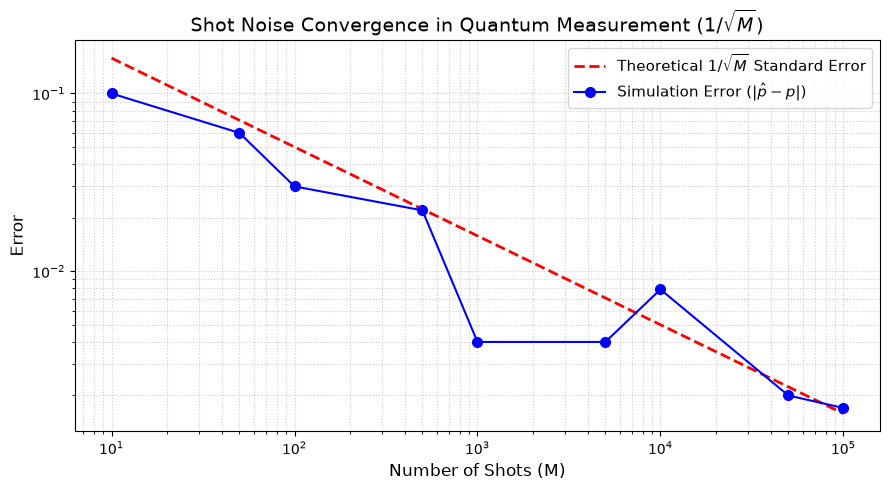

M = 100일 때의 이론 오차:    0.05000
M = 10,000일 때의 이론 오차: 0.00500
=> 샷 수가 100배(100 -> 10,000) 늘어나면 오차는 정확히 10.0배(1/10로) 줄어듭니다!


In [12]:
shot_list = [10, 50, 100, 500, 1000, 5000, 10000, 50000, 100000]
true_p0 = 0.5  # |+> 상태에서 0이 관측될 이론적 확률
empirical_errors = []
theoretical_errors = []

np.random.seed(42)
for m in shot_list:
    counts = sample_measurements(plus_state, shots=m)
    p0_obs = counts["0"] / m
    err = abs(p0_obs - true_p0)
    empirical_errors.append(err)
    
    # 중심극한정리 이론적 표준오차: sqrt(p*(1-p)/M)
    std_err = np.sqrt(true_p0 * (1.0 - true_p0) / m)
    theoretical_errors.append(std_err)

# [완성형 시각화 플롯]
plt.figure(figsize=(9, 5))
plt.loglog(shot_list, theoretical_errors, "r--", label=r"Theoretical $1/\sqrt{M}$ Standard Error", linewidth=2)
plt.loglog(shot_list, empirical_errors, "bo-", label=r"Simulation Error ($|\hat{p} - p|$)", markersize=7)
plt.xlabel("Number of Shots (M)", fontsize=12)
plt.ylabel("Error", fontsize=12)
plt.title(r"Shot Noise Convergence in Quantum Measurement ($1/\sqrt{M}$)", fontsize=14)
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.legend(fontsize=11)
plt.tight_layout()
plt.show()

# [정량적 관찰 및 생각거리]
idx_100 = shot_list.index(100)
idx_10000 = shot_list.index(10000)
ratio = theoretical_errors[idx_100] / theoretical_errors[idx_10000]

print(f"M = 100일 때의 이론 오차:    {theoretical_errors[idx_100]:.5f}")
print(f"M = 10,000일 때의 이론 오차: {theoretical_errors[idx_10000]:.5f}")
print(f"=> 샷 수가 100배(100 -> 10,000) 늘어나면 오차는 정확히 {ratio:.1f}배(1/10로) 줄어듭니다!")


---
### 6. 1일차 총정리 & 2일차 예고 (단일 큐비트의 수학적 모델)

오늘 1일차 이론과 실습에서는 외부 양자 프레임워크 없이, **순수 Python과 NumPy**만으로 양자역학의 핵심 선형대수학적 원리를 체득했습니다.

#### 오늘 정리한 3대 선형대수학적 원리
1. **상태의 본질: 2차원 복소 단위벡터**
   - 단일 큐비트의 물리적 상태는 2차원 복소 내적 공간 $\mathbb{C}^2$ 상의 크기가 1인 단위벡터 $\begin{pmatrix} \alpha \\ \beta \end{pmatrix}$로 엄밀히 표현됩니다 ($|\alpha|^2 + |\beta|^2 = 1$).

2. **게이트의 본질: 유니터리 변환 행렬**
   - $X, Y, Z, H, S, T$ 등 모든 단일 큐비트 양자 게이트는 상태벡터의 길이를 보존하는 $2 \times 2$ 유니터리 행렬($U^* U = I$)입니다.
   - 특히 Hadamard 게이트는 계산 기저($Z$축)와 중첩 기저($X$축)를 1:1로 가역 변환하며 자기 역원($H^2 = I$)의 대수적 성질을 가집니다.

3. **측정의 본질: Born 규칙과 사영 붕괴**
   - 임의의 중첩 상태라도 계산 기저에서 측정하는 순간 확률적으로 기저 $|0\rangle$ 또는 $|1\rangle$ 중 하나로 비가역적으로 붕괴합니다 ($P(0)=|\alpha|^2, P(1)=|\beta|^2$).
   - 유한한 측정 횟수($M$)에서 표본 통계 오차는 대수의 법칙에 의해 $1/\sqrt{M}$의 속도로 줄어듭니다.

---
#### 2일차 예고: 다중 큐비트와 상태공간 확장
> "큐비트가 결합하면 상태공간의 차원은 왜 지수적으로 팽창($2^n$)하며, 독립된 상태로 분리할 수 없는 **양자 얽힘(Entanglement)**은 어떻게 만들어지는가?"
>
> 다음 시간에는 텐서곱($\otimes$, Kronecker Product)을 도입하여 $2$차원에서 $4$차원 복소 공간으로 확장하고, 양자 컴퓨팅 최대의 계산 자원인 **Bell State(벨 상태)**를 직접 구현합니다.
